In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from risk.data.data import load_prices, calculate_returns
from risk.stats import summary_table
from risk.var import historical_var, parametric_var, garch_var, calculate_vars
from risk.es import calculate_es
from risk.backtest import rolling_var, backtest_summary

In [2]:
tickers = ["SPY", "IEF", "QQQ", "GLD", "USO"]
data = load_prices(tickers, start="2015-01-01", end="2025-12-31")

returns = calculate_returns(data, {
    "SPY": 0.3, 
    "IEF": 0.3, 
    "QQQ": 0.2, 
    "GLD": 0.1, 
    "USO": 0.1})

[*********************100%***********************]  5 of 5 completed


In [3]:
summary_table(returns)

,Value
Annual Mean,0.080036
Volatility,0.114466
Skewness,-0.826901
Kurtosis,12.593345
Jarque-Bera p-value,0.000000


In [4]:
pd.concat([calculate_vars(returns, 0.99),
           calculate_es(returns, 0.975)], axis=1).style.format("{:.2%}")

,VaR Estimates,Expected Shortfall
Historical,2.06%,2.24%
Parametric (normal),1.65%,1.65%
Monte Carlo (normal),1.66%,1.66%
Monte Carlo (t),1.93%,2.11%
GARCH (normal),1.02%,1.02%
GARCH (t),1.11%,1.16%


In [5]:
window = 500
results = {
    "Historical": rolling_var(returns, historical_var, 0.99, window=window),
    "Parametric": rolling_var(returns, parametric_var, 0.99, window=window),
    "GARCH (t)": rolling_var(
        returns, lambda r, c: garch_var(r, c, dist="t"),
        0.99, window=window, step=1),
}

backtest_summary(results, 0.99)

,Observations,Breaches,Expected breaches,Breach rate,Kupiec p-value,Christoffersen p-value
Historical,2264,31,22.64,0.014,0.095,0.001
Parametric,2264,57,22.64,0.025,0.000,0.000
GARCH (t),2264,39,22.64,0.017,0.002,0.180


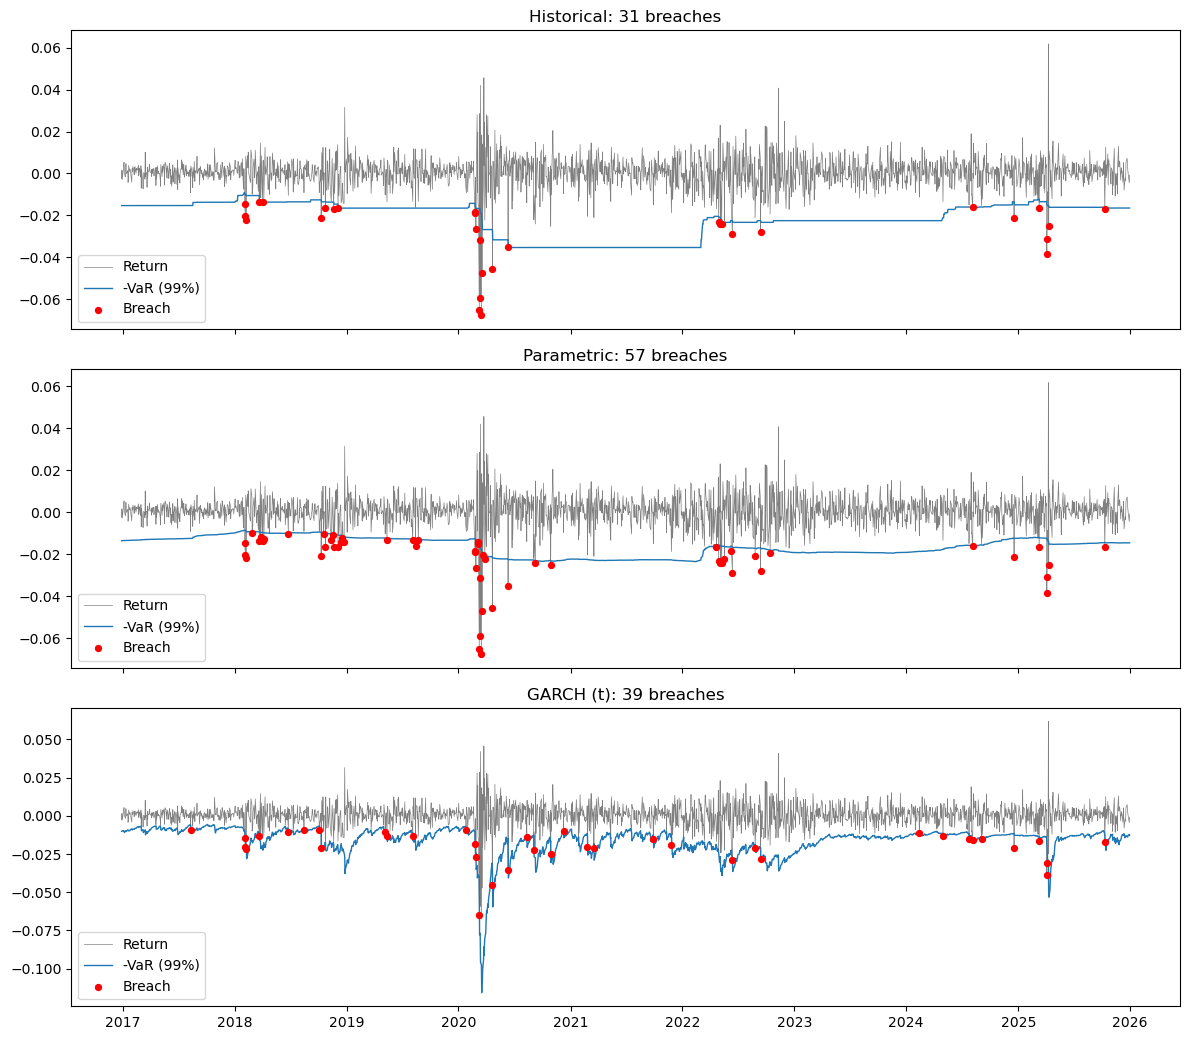

In [6]:
fig, axes = plt.subplots(len(results), 1, figsize=(12, 3.5 * len(results)), sharex=True)
for ax, (name, res) in zip(axes, results.items()):
    ax.plot(res.index, res["return"], lw=0.5, color="gray", label="Return")
    ax.plot(res.index, -res["var"], color="tab:blue", lw=1, label="-VaR (99%)")
    b = res[res["breach"]]
    ax.scatter(b.index, b["return"], color="red", s=18, zorder=3, label="Breach")
    ax.set_title(f"{name}: {int(res['breach'].sum())} breaches")
    ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("results/breaches.png", dpi=150)

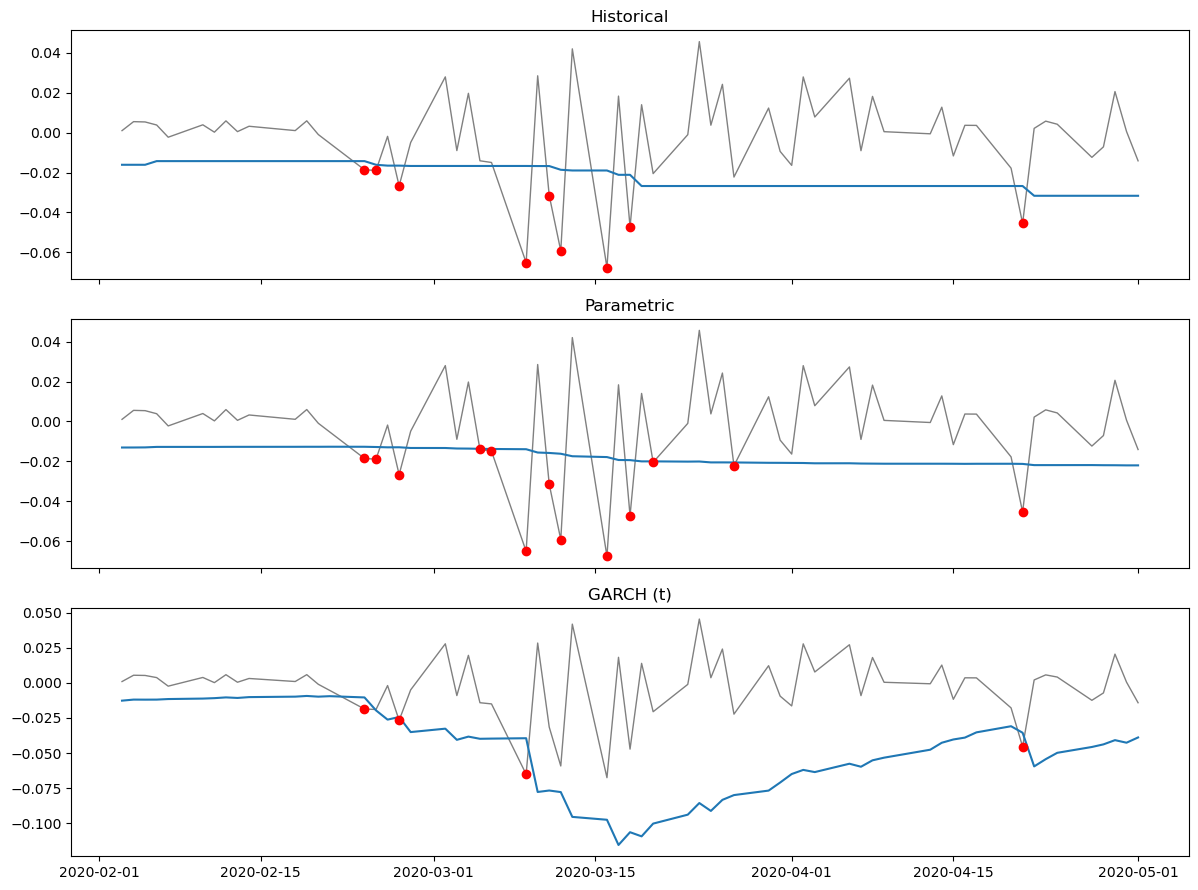

In [7]:
fig, axes = plt.subplots(len(results), 1, figsize=(12, 3 * len(results)), sharex=True)
for ax, (name, res) in zip(axes, results.items()):
    z = res.loc["2020-02-01":"2020-05-01"]
    ax.plot(z.index, z["return"], color="gray", lw=1)
    ax.plot(z.index, -z["var"], color="tab:blue")
    ax.scatter(z[z["breach"]].index, z[z["breach"]]["return"], color="red", zorder=3)
    ax.set_title(name)
fig.tight_layout()



In [8]:
%%capture
!python -m jupyter nbconvert --to html --no-input analysis.ipynb --output report --output-dir results